In [5]:
import sys, time, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patches as mp
from utils_cv import baca, tampil, kontras_bercak
from praproses import (praproses, praproses_adaptif, deteksi_kondisi,
                       simpan_param, simpan_cfg, muat_param, PARAM_BAWAAN)
KANAL = 2 # indeks BGR: 2 = R (kanal terbaik di Bagian 2)
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("../data/sintetis/label.csv")
def muat(nama):
    return (baca(f"../data/sintetis/citra/{nama}"),
            cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0),
            cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0))

In [6]:
img, _, _ = muat("teh_041.png")
print("640x480 ->", praproses(img).shape)
besar = cv2.resize(img, (4000, 3000))
print("4000x3000 ->", praproses(besar).shape)

640x480 -> (480, 640, 3)
4000x3000 -> (480, 640, 3)


In [7]:
import itertools
ARAH = {"normal": lambda g: g == 1.0, "gelap": lambda g: g <= 1.0, "terang": lambda g: g >= 1.0,
        "kontras_rendah": lambda g: g <= 1.0, "bayangan": lambda g: g <= 1.0}
PENAPIS = {"median3": {"penapis": "median", "kernel": 3},
           "gauss5": {"penapis": "gaussian", "kernel": 5, "sigma": 1.0}}
data = {kd: [(d.kelas, *muat(d.nama_file)) for _, d in label[label.kondisi_cahaya == kd].iterrows()] for kd in URUT}
grid = []
for kd in URUT:
    for pn, g, cl, t in itertools.product(PENAPIS, [0.7, 0.85, 1.0, 1.3, 1.6], [0, 1.0, 2.0], [0, 0.5]):
        p = {"gamma": g, "clahe_clip": cl, "tajam_k": t, **PENAPIS[pn]}
        kb0, kb1, s0, s1 = [], [], [], []
        for kelas, img, md, mb in data[kd]:
            out = praproses(img, p)
            if kelas == "sehat":
                s0.append(img[:, :, KANAL][md > 0].std()); s1.append(out[:, :, KANAL][md > 0].std())
            else:
                kb0.append(kontras_bercak(img[:, :, KANAL], md, mb)); kb1.append(kontras_bercak(out[:, :, KANAL], md, mb))
        grid.append([kd, pn, g, cl, t, np.mean(kb0), np.mean(kb1), np.mean(s0), np.mean(s1)])
grid = pd.DataFrame(grid, columns=["kondisi", "penapis", "gamma", "clahe", "tajam", "KB_asli", "KB", "sd_sehat_asli", "sd_sehat"])
grid["syarat_arah"] = [ARAH[k](g) for k, g in zip(grid.kondisi, grid.gamma)]
grid["syarat_sehat"] = grid.sd_sehat <= grid.sd_sehat_asli
grid.round(3).to_csv("../hasil/b5_grid_parameter.csv", index=False)

lolos = grid[grid.syarat_arah & grid.syarat_sehat]
terbaik = lolos.loc[lolos.groupby(["penapis", "kondisi"]).KB.idxmax()]
print("Terbaik yang memenuhi syarat:")
print(terbaik[["penapis", "kondisi", "gamma", "clahe", "tajam", "KB_asli", "KB", "sd_sehat_asli", "sd_sehat"]].round(2).to_string(index=False))
print("\nRerata KB terbaik per penapis:", terbaik.groupby("penapis").KB.mean().round(2).to_dict())
tanpa = grid.loc[grid.groupby("kondisi").KB.idxmax()]
print("\nTerbaik TANPA syarat (perhatikan gamma pada gelap/bayangan/kontras rendah):")
print(tanpa[["kondisi", "penapis", "gamma", "clahe", "tajam", "KB"]].round(2).to_string(index=False))

Terbaik yang memenuhi syarat:
penapis        kondisi  gamma  clahe  tajam  KB_asli    KB  sd_sehat_asli  sd_sehat
 gauss5       bayangan    1.0    2.0    0.0     4.83  8.32          14.20      9.51
 gauss5          gelap    1.0    1.0    0.5     8.56 14.75           9.13      6.31
 gauss5 kontras_rendah    1.0    0.0    0.0     3.07  8.26           9.17      3.55
 gauss5         normal    1.0    0.0    0.5     9.46 12.68          13.71      7.90
 gauss5         terang    1.6    0.0    0.0     5.58 11.25          10.74      7.08
median3       bayangan    1.0    2.0    0.0     4.83  8.08          14.20     10.04
median3          gelap    1.0    1.0    0.0     8.56 15.08           9.13      5.79
median3 kontras_rendah    1.0    0.0    0.0     3.07  6.65           9.17      4.24
median3         normal    1.0    0.0    0.5     9.46 13.93          13.71      8.30
median3         terang    1.6    0.0    0.0     5.58 11.10          10.74      7.11

Rerata KB terbaik per penapis: {'gauss5': 11.

In [8]:
g = grid[(grid.penapis == "median3") & (grid.kondisi == "gelap") & (grid.gamma == 1.0) & (grid.tajam == 0)]
print(g[["clahe", "KB", "sd_sehat"]].round(2).to_string(index=False))

 clahe    KB  sd_sehat
   0.0 14.80      5.28
   1.0 15.08      5.79
   2.0 14.46      6.40


In [9]:

param_contoh = {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3}
simpan_param(param_contoh, "../hasil/param_contoh_modul.json")

param_tetap = {"gamma": 1.0, "clahe_clip": 0, "penapis": "median", "kernel": 3, "tajam_k": 0.0}
CFG = {
    "kanal_evaluasi": "R",
    "dasar": param_tetap,
    "per_kondisi": {
        "terang": {"gamma": 1.6},
        "bayangan": {"clahe_clip": 1.0, "clahe_tile": 8},
    },
    "ambang": {"bayangan_lr": 40, "terang_rerata": 190, "kontras_std": 25, "gelap_rerata": 145},
}
simpan_cfg(CFG, "../hasil/param_praproses.json")
print(json.dumps(muat_param("../hasil/param_praproses.json"), indent=2))

{
  "kanal_evaluasi": "R",
  "dasar": {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
  },
  "per_kondisi": {
    "terang": {
      "gamma": 1.6
    },
    "bayangan": {
      "clahe_clip": 1.0,
      "clahe_tile": 8
    }
  },
  "ambang": {
    "bayangan_lr": 40,
    "terang_rerata": 190,
    "kontras_std": 25,
    "gelap_rerata": 145
  }
}


In [10]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    a = praproses(img, param_contoh)
    b = praproses(img, param_tetap)
    t0 = time.perf_counter(); c_, kd = praproses_adaptif(img, CFG); dt = 1000 * (time.perf_counter() - t0)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, kd,
                  kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(a[:, :, KANAL], md, mb),
                  kontras_bercak(b[:, :, KANAL], md, mb),
                  kontras_bercak(c_[:, :, KANAL], md, mb), dt])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "kondisi_terdeteksi", "KB_sebelum",
                                  "KB_contoh_modul", "KB_tetap", "KB_adaptif", "waktu_ms"])
print("Deteksi kondisi benar:", (ev.kondisi == ev.kondisi_terdeteksi).mean())
print(f"Waktu praproses adaptif: rerata {ev.waktu_ms.mean():.2f} ms per citra 640x480")
banding = ev.groupby("kondisi")[["KB_sebelum", "KB_contoh_modul", "KB_tetap", "KB_adaptif"]].mean().loc[URUT].round(2)
banding.loc["rerata"] = banding.mean().round(2)
print(banding)
ev.to_csv("../hasil/b5_evaluasi_per_citra.csv", index=False)

Deteksi kondisi benar: 1.0
Waktu praproses adaptif: rerata 1.86 ms per citra 640x480
                KB_sebelum  KB_contoh_modul  KB_tetap  KB_adaptif
kondisi                                                          
normal                9.46            10.37     13.92       13.92
gelap                 8.56            14.46     14.80       14.80
terang                5.58             5.58      9.85       11.10
kontras_rendah        3.07             4.30      6.65        6.65
bayangan              4.83             8.08      6.00        7.85
rerata                6.30             8.56     10.24       10.86


                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
normal                9.46       13.92        47.22
gelap                 8.56       14.80        72.90
terang                5.58       11.10        98.98
kontras_rendah        3.07        6.65       116.48
bayangan              4.83        7.85        62.74


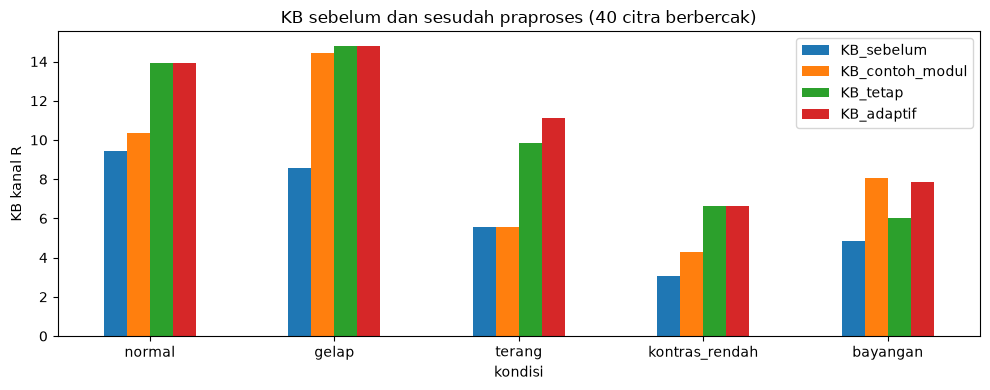

In [11]:
tabel12 = ev.groupby("kondisi")[["KB_sebelum", "KB_adaptif"]].mean().loc[URUT]
tabel12.columns = ["KB_sebelum", "KB_sesudah"]
tabel12["perubahan_%"] = 100 * (tabel12.KB_sesudah - tabel12.KB_sebelum) / tabel12.KB_sebelum
tabel12 = tabel12.round(2); print(tabel12)
tabel12.to_csv("../hasil/b5_tabel12.csv")

ax = banding.drop("rerata")[["KB_sebelum", "KB_contoh_modul", "KB_tetap", "KB_adaptif"]].plot.bar(figsize=(10, 4))
ax.set_ylabel("KB kanal R"); ax.set_title("KB sebelum dan sesudah praproses (40 citra berbercak)")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("../hasil/b5_kb_praproses.png", dpi=120); plt.show()

In [12]:
print(ev.groupby(["kelas", "kondisi"])[["KB_sebelum", "KB_adaptif"]].mean().round(2).unstack(0))
print("\nJumlah citra yang KB-nya turun:", (ev.KB_adaptif < ev.KB_sebelum).sum(), "dari", len(ev))

               KB_sebelum        KB_adaptif       
kelas               berat ringan      berat ringan
kondisi                                           
bayangan             5.29   4.36       8.79   6.91
gelap                9.01   8.11      15.86  13.75
kontras_rendah       3.26   2.89       7.11   6.18
normal              10.41   8.51      15.67  12.17
terang               6.06   5.09      11.90  10.30

Jumlah citra yang KB-nya turun: 0 dari 40


In [13]:
bs = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, _ = muat(d.nama_file)
    daun = md > 0
    a = praproses(img, param_contoh)
    c_, _ = praproses_adaptif(img, CFG)
    bs.append([d.kondisi_cahaya, img[:, :, KANAL][daun].std(),
               a[:, :, KANAL][daun].std(), c_[:, :, KANAL][daun].std()])
sehat = pd.DataFrame(bs, columns=["kondisi", "std_sebelum", "std_contoh_modul", "std_adaptif"])
uji_sehat = sehat.groupby("kondisi").mean().loc[URUT].round(2)
uji_sehat["perubahan_adaptif_%"] = (100 * (uji_sehat.std_adaptif - uji_sehat.std_sebelum) / uji_sehat.std_sebelum).round(1)
print(uji_sehat); uji_sehat.to_csv("../hasil/b5_uji_bercak_palsu.csv")

                std_sebelum  std_contoh_modul  std_adaptif  \
kondisi                                                      
normal                13.71             10.61         7.67   
gelap                  9.13              6.40         5.28   
terang                10.74             12.55         7.11   
kontras_rendah         9.17              9.22         4.24   
bayangan              14.20             10.04         9.22   

                perubahan_adaptif_%  
kondisi                              
normal                        -44.1  
gelap                         -42.2  
terang                        -33.8  
kontras_rendah                -53.8  
bayangan                      -35.1  


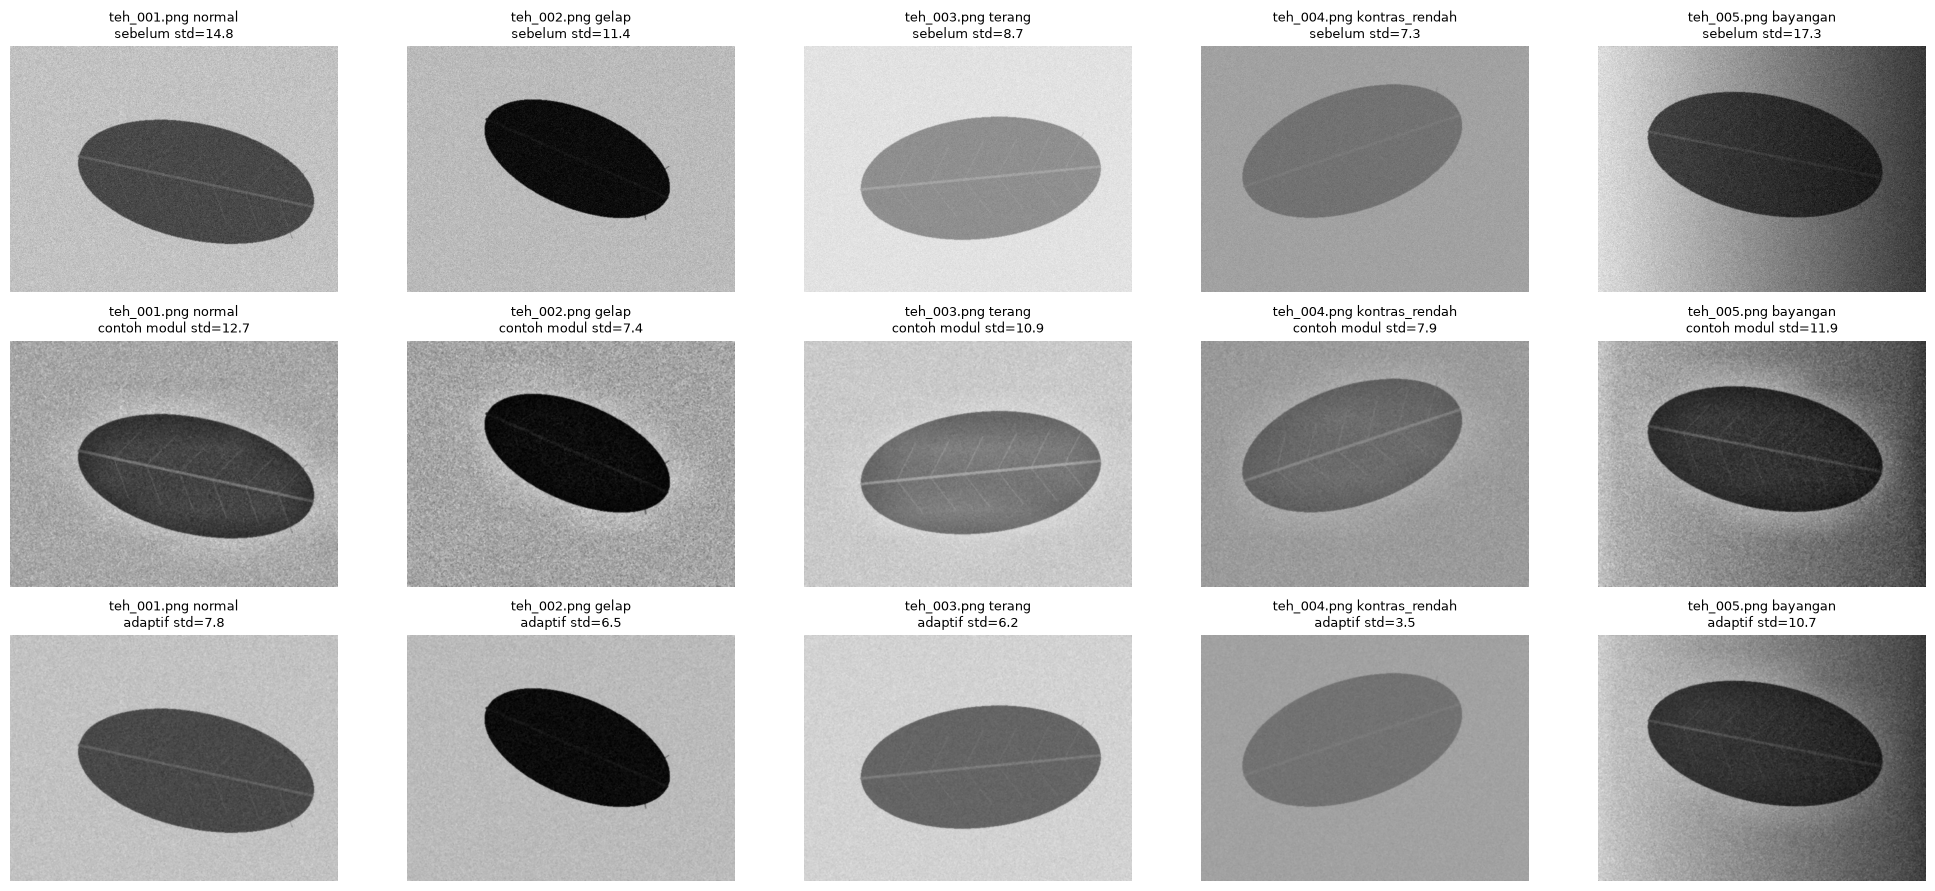

In [14]:
fig, ax = plt.subplots(3, 5, figsize=(20, 9))
for j, nama in enumerate([f"teh_{i:03d}.png" for i in range(1, 6)]):
    img, md, _ = muat(nama)
    a = praproses(img, param_contoh); c_, kd = praproses_adaptif(img, CFG)
    for i, (x, jd) in enumerate([(img, "sebelum"), (a, "contoh modul"), (c_, "adaptif")]):
        ax[i, j].imshow(x[:, :, KANAL], cmap="gray", vmin=0, vmax=255)
        ax[i, j].set_title(f"{nama} {kd}\n{jd} std={x[:, :, KANAL][md > 0].std():.1f}", fontsize=9); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig("../hasil/b5_uji_bercak_palsu.png", dpi=100); plt.show()

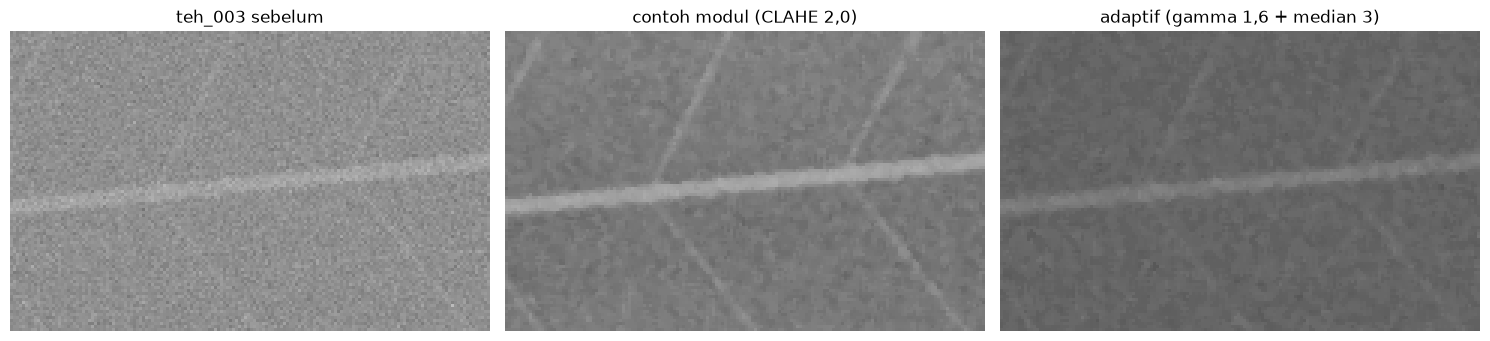

In [15]:
img, md, _ = muat("teh_003.png")
a = praproses(img, param_contoh); c_, _ = praproses_adaptif(img, CFG)
ys, xs = np.where(md > 0); cy, cx = int(ys.mean()), int(xs.mean())
pot = lambda x: cv2.resize(x[cy-50:cy+50, cx-80:cx+80, KANAL], None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST)
tampil([pot(img), pot(a), pot(c_)], ["teh_003 sebelum", "contoh modul (CLAHE 2,0)", "adaptif (gamma 1,6 + median 3)"], ukuran=(15, 3.6))
plt.savefig("../hasil/b5_zoom_sehat_terang.png", dpi=110); plt.show()

In [16]:
ab = []
for k in [0.0, 0.5, 1.0]:
    cfg_k = {**CFG, "dasar": {**CFG["dasar"], "tajam_k": k}}
    kb, sd = [], []
    for _, d in label.iterrows():
        img, md, mb = muat(d.nama_file)
        out, _ = praproses_adaptif(img, cfg_k)
        if d.kelas == "sehat":
            sd.append(out[:, :, KANAL][md > 0].std())
        else:
            kb.append(kontras_bercak(out[:, :, KANAL], md, mb))
    ab.append([k, np.mean(kb), np.mean(sd)])
ablasi = pd.DataFrame(ab, columns=["tajam_k", "KB_rerata_40_berbercak", "std_daun_sehat_rerata"]).round(2)
print(ablasi); ablasi.to_csv("../hasil/b5_ablasi_tajam.csv", index=False)

   tajam_k  KB_rerata_40_berbercak  std_daun_sehat_rerata
0      0.0                   10.87                   6.70
1      0.5                   10.30                   7.27
2      1.0                    9.49                   8.08


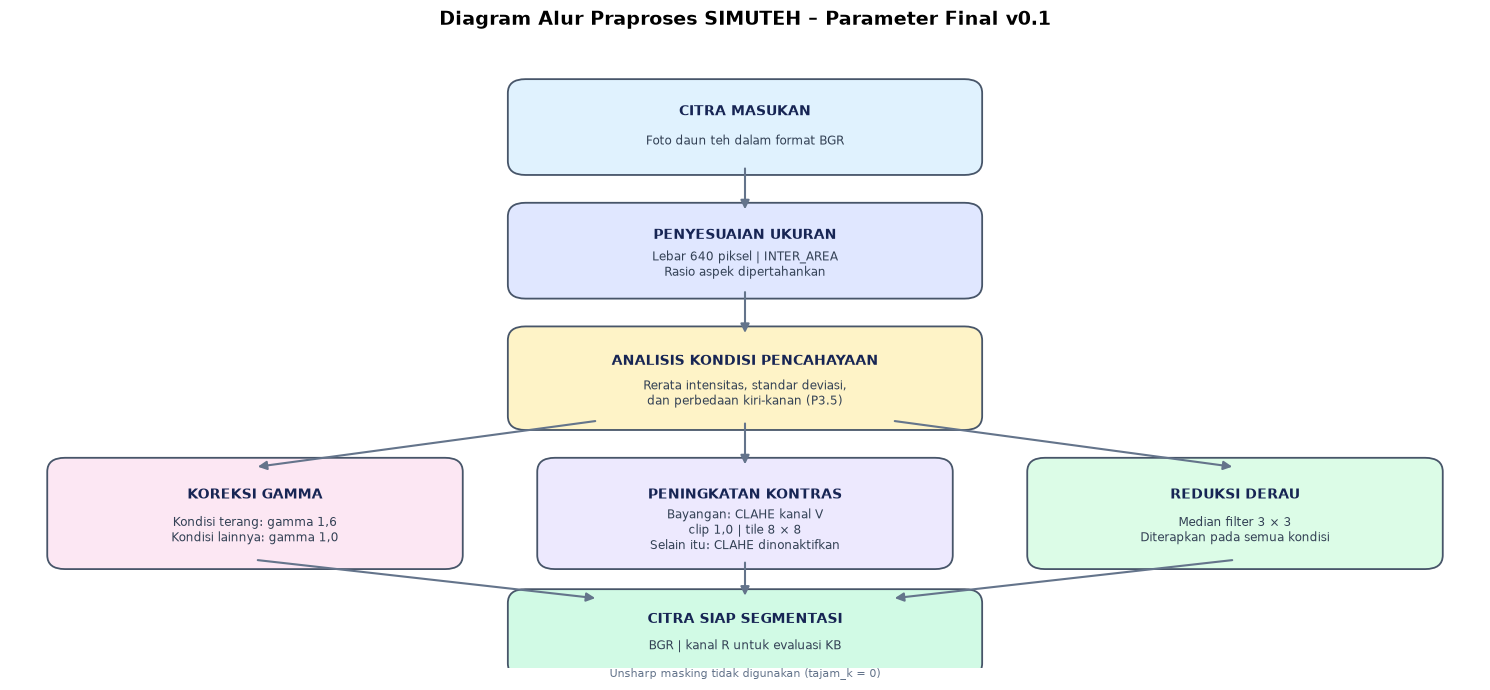

In [18]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(15, 7))
ax.set_xlim(0, 15)
ax.set_ylim(0, 8)
ax.axis("off")

def kotak(x, y, w, h, judul, isi, warna):
    box = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12,rounding_size=0.18",
        linewidth=1.3,
        edgecolor="#475569",
        facecolor=warna
    )
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.70, judul,
            ha="center", va="center",
            fontsize=10, fontweight="bold", color="#172554")
    ax.text(x+w/2, y+h*0.32, isi,
            ha="center", va="center",
            fontsize=8.5, color="#334155")

def panah(x1, y1, x2, y2):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=1.5,
            color="#64748b",
            mutation_scale=13
        )
    )

# Tahap awal
kotak(5.2, 6.5, 4.6, 1.0,
      "CITRA MASUKAN",
      "Foto daun teh dalam format BGR",
      "#e0f2fe")

kotak(5.2, 4.9, 4.6, 1.0,
      "PENYESUAIAN UKURAN",
      "Lebar 640 piksel | INTER_AREA\nRasio aspek dipertahankan",
      "#e0e7ff")

kotak(5.2, 3.2, 4.6, 1.1,
      "ANALISIS KONDISI PENCAHAYAAN",
      "Rerata intensitas, standar deviasi,\ndan perbedaan kiri-kanan (P3.5)",
      "#fef3c7")

panah(7.5, 6.5, 7.5, 5.9)
panah(7.5, 4.9, 7.5, 4.3)

# Cabang keputusan gamma
kotak(0.5, 1.4, 4.0, 1.2,
      "KOREKSI GAMMA",
      "Kondisi terang: gamma 1,6\nKondisi lainnya: gamma 1,0",
      "#fce7f3")

# Cabang keputusan CLAHE
kotak(5.5, 1.4, 4.0, 1.2,
      "PENINGKATAN KONTRAS",
      "Bayangan: CLAHE kanal V\nclip 1,0 | tile 8 × 8\nSelain itu: CLAHE dinonaktifkan",
      "#ede9fe")

# Denoising
kotak(10.5, 1.4, 4.0, 1.2,
      "REDUKSI DERAU",
      "Median filter 3 × 3\nDiterapkan pada semua kondisi",
      "#dcfce7")

# Cabang dari analisis kondisi
panah(6.0, 3.2, 2.5, 2.6)
panah(7.5, 3.2, 7.5, 2.6)
panah(9.0, 3.2, 12.5, 2.6)

# Penggabungan menuju hasil
kotak(5.2, 0.0, 4.6, 0.9,
      "CITRA SIAP SEGMENTASI",
      "BGR | kanal R untuk evaluasi KB",
      "#d1fae5")

panah(2.5, 1.4, 6.0, 0.9)
panah(7.5, 1.4, 7.5, 0.9)
panah(12.5, 1.4, 9.0, 0.9)

# Keterangan penajaman
ax.text(
    7.5, 0.0,
    "Unsharp masking tidak digunakan (tajam_k = 0)",
    ha="center", va="top",
    fontsize=8, color="#64748b"
)

ax.set_title(
    "Diagram Alur Praproses SIMUTEH – Parameter Final v0.1",
    fontsize=14, fontweight="bold", pad=18
)

plt.tight_layout()
plt.savefig(
    "../hasil/b5_diagram_praproses.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
